# Battery Remaining Useful Life (RUL) Prediction using XGBoost

This notebook builds an end-to-end machine learning pipeline to predict the **Remaining Useful Life (RUL)** of a lithium-ion battery (in charge/discharge cycles) using **XGBoost Regression**.

**Note on dataset:** A synthetic battery degradation dataset is generated in this notebook, modeled on real-world lithium-ion cycling behavior (e.g., NASA Li-ion battery datasets), so that the notebook runs end-to-end without requiring an external file. If you have your own battery dataset (CSV with columns like `cycle`, `voltage`, `current`, `temperature`, `capacity`, etc.), simply replace the data-loading cell (Step 2) with `pd.read_csv('your_file.csv')`.


## 1. Import Required Libraries

In [1]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from xgboost import XGBRegressor

import warnings
warnings.filterwarnings('ignore')

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 5)

print("Libraries imported successfully.")


Libraries imported successfully.


## 2. Load the Dataset

We simulate a realistic multi-battery cycling dataset. Each battery starts at ~2.0 Ah rated capacity and degrades
(roughly exponentially with noise) over hundreds of charge/discharge cycles until it reaches the common
**End-of-Life (EOL) threshold of 70-80% of rated capacity**. Sensor-like features (voltage, current, temperature,
internal resistance) are generated to correlate with the degradation state, similar to real battery telemetry.


In [2]:
np.random.seed(42)

def generate_battery_data(battery_id, n_cycles, rated_capacity=2.0):
    cycle = np.arange(1, n_cycles + 1)

    # Capacity fade: exponential decay + mild random degradation noise + occasional regeneration bumps
    decay_rate = np.random.uniform(0.0022, 0.0032)
    noise = np.random.normal(0, 0.01, n_cycles)
    capacity = rated_capacity * np.exp(-decay_rate * cycle) + noise
    capacity = np.clip(capacity, 0.5, rated_capacity)

    ambient_temperature = np.random.choice([24, 25, 26, 43, 44], size=n_cycles)
    temperature_measured = ambient_temperature + 8 * (1 - capacity / rated_capacity) + np.random.normal(0, 1.2, n_cycles)
    voltage_measured = 4.2 - 0.55 * (1 - capacity / rated_capacity) + np.random.normal(0, 0.03, n_cycles)
    current_measured = -2.0 + np.random.normal(0, 0.05, n_cycles)
    internal_resistance = 0.05 + 0.09 * (1 - capacity / rated_capacity) + np.random.normal(0, 0.003, n_cycles)
    charge_time = 3000 + 1800 * (1 - capacity / rated_capacity) + np.random.normal(0, 60, n_cycles)
    discharge_time = 3500 - 1200 * (1 - capacity / rated_capacity) + np.random.normal(0, 60, n_cycles)

    df = pd.DataFrame({
        'battery_id': battery_id,
        'cycle': cycle,
        'ambient_temperature': ambient_temperature,
        'voltage_measured': voltage_measured,
        'current_measured': current_measured,
        'temperature_measured': temperature_measured,
        'internal_resistance': internal_resistance,
        'charge_time_s': charge_time,
        'discharge_time_s': discharge_time,
        'capacity': capacity,
        'rated_capacity': rated_capacity
    })
    return df

battery_ids = ['B0001', 'B0002', 'B0003', 'B0004', 'B0005', 'B0006']
n_cycles_list = [620, 580, 700, 540, 660, 610]

battery_frames = [generate_battery_data(bid, n) for bid, n in zip(battery_ids, n_cycles_list)]
df = pd.concat(battery_frames, ignore_index=True)

# End-of-Life threshold at 70% of rated capacity -> define RUL (cycles remaining until EOL)
eol_fraction = 0.70
df['eol_capacity'] = df['rated_capacity'] * eol_fraction

def get_eol_cycle(group):
    eol_cap = group['eol_capacity'].iloc[0]
    below_eol = group.loc[group['capacity'] <= eol_cap, 'cycle']
    return below_eol.min() if not below_eol.empty else group['cycle'].max()

eol_cycle_per_battery = df.groupby('battery_id').apply(get_eol_cycle)
df['eol_cycle'] = df['battery_id'].map(eol_cycle_per_battery)
df['RUL'] = (df['eol_cycle'] - df['cycle']).clip(lower=0)
df = df.drop(columns=['eol_cycle'])

# Introduce a few random missing values to demonstrate handling missing data (Step 4)
missing_idx = df.sample(frac=0.015, random_state=42).index
df.loc[missing_idx, 'internal_resistance'] = np.nan
df.loc[df.sample(frac=0.01, random_state=7).index, 'temperature_measured'] = np.nan

print("Dataset generated with shape:", df.shape)
df.head()


Dataset generated with shape: (3710, 13)


,battery_id,cycle,ambient_temperature,voltage_measured,current_measured,temperature_measured,internal_resistance,charge_time_s,discharge_time_s,capacity,rated_capacity,eol_capacity,RUL
0,B0001,1,44,4.223863,-1.966900,44.187162,0.054125,3070.934076,3404.308325,1.983739,2.0,1.4,138
1,B0001,2,44,4.177375,-1.973051,43.699493,0.052570,2951.099697,3462.117687,1.992917,2.0,1.4,137
2,B0001,3,25,4.187462,-1.994374,25.303071,0.050961,3034.848215,3432.090390,1.987403,2.0,1.4,136
3,B0001,4,43,4.172695,-1.950842,44.097897,0.049245,2871.963998,3391.210131,1.989615,2.0,1.4,135
4,B0001,5,24,4.127374,-2.032815,25.896581,0.053516,2995.213155,3520.247190,1.968611,2.0,1.4,134


## 3. Explore the Dataset

In [3]:
df.head(10)

,battery_id,cycle,ambient_temperature,voltage_measured,current_measured,temperature_measured,internal_resistance,charge_time_s,discharge_time_s,capacity,rated_capacity,eol_capacity,RUL
0,B0001,1,44,4.223863,-1.966900,44.187162,0.054125,3070.934076,3404.308325,1.983739,2.0,1.4,138
1,B0001,2,44,4.177375,-1.973051,43.699493,0.052570,2951.099697,3462.117687,1.992917,2.0,1.4,137
2,B0001,3,25,4.187462,-1.994374,25.303071,0.050961,3034.848215,3432.090390,1.987403,2.0,1.4,136
3,B0001,4,43,4.172695,-1.950842,44.097897,0.049245,2871.963998,3391.210131,1.989615,2.0,1.4,135
4,B0001,5,24,4.127374,-2.032815,25.896581,0.053516,2995.213155,3520.247190,1.968611,2.0,1.4,134
5,B0001,6,24,4.189029,-2.039635,25.972056,0.048235,3156.978536,3399.310897,1.964091,2.0,1.4,133
6,B0001,7,26,4.192459,-1.962695,26.612090,0.056468,3099.462559,3534.174648,1.958565,2.0,1.4,132
7,B0001,8,44,4.218222,-2.081252,43.993731,0.051718,3137.139050,3493.637007,1.949988,2.0,1.4,131
8,B0001,9,24,4.204081,-1.995391,24.463235,0.054152,3024.702542,3474.499803,1.928066,2.0,1.4,130
9,B0001,10,44,4.212903,-2.015828,44.791864,0.049131,3043.423309,3575.120584,1.958670,2.0,1.4,129


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3710 entries, 0 to 3709
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   battery_id            3710 non-null   str    
 1   cycle                 3710 non-null   int64  
 2   ambient_temperature   3710 non-null   int64  
 3   voltage_measured      3710 non-null   float64
 4   current_measured      3710 non-null   float64
 5   temperature_measured  3673 non-null   float64
 6   internal_resistance   3654 non-null   float64
 7   charge_time_s         3710 non-null   float64
 8   discharge_time_s      3710 non-null   float64
 9   capacity              3710 non-null   float64
 10  rated_capacity        3710 non-null   float64
 11  eol_capacity          3710 non-null   float64
 12  RUL                   3710 non-null   int64  
dtypes: float64(9), int64(3), str(1)
memory usage: 376.9 KB


In [5]:
df.describe()

,cycle,ambient_temperature,voltage_measured,current_measured,temperature_measured,internal_resistance,charge_time_s,discharge_time_s,capacity,rated_capacity,eol_capacity,RUL
count,3710.000000,3710.000000,3710.000000,3710.000000,3673.000000,3654.000000,3710.000000,3710.000000,3710.000000,3710.0,3710.0,3710.000000
mean,311.834232,32.447439,3.924586,-1.998435,36.448026,0.094927,3902.510811,2899.859367,0.999748,2.0,1.4,14.692453
std,182.244146,9.118661,0.125344,0.050476,9.363797,0.020193,402.882082,272.723079,0.443145,0.0,0.0,33.429064
min,1.000000,24.000000,3.674777,-2.180383,21.503811,0.045748,2871.963998,2425.931673,0.500000,2.0,1.4,0.000000
25%,155.000000,25.000000,3.818769,-2.031915,28.614174,0.079911,3604.880199,2667.268119,0.597490,2.0,1.4,0.000000
50%,310.000000,26.000000,3.898525,-1.998367,31.287640,0.099716,4000.609897,2843.171110,0.894419,2.0,1.4,0.000000
75%,464.000000,43.000000,4.018011,-1.964032,47.052378,0.112722,4256.970310,3103.877287,1.337421,2.0,1.4,0.000000
max,700.000000,44.000000,4.252646,-1.822177,54.089661,0.126069,4511.729323,3607.327696,2.000000,2.0,1.4,145.000000


In [6]:
print('Shape of dataset (rows, columns):', df.shape)

Shape of dataset (rows, columns): (3710, 13)


In [7]:
print("Unique batteries:", df['battery_id'].unique())
print("\nCycles per battery:")
print(df.groupby('battery_id')['cycle'].max())


Unique batteries: <StringArray>
['B0001', 'B0002', 'B0003', 'B0004', 'B0005', 'B0006']
Length: 6, dtype: str

Cycles per battery:
battery_id
B0001    620
B0002    580
B0003    700
B0004    540
B0005    660
B0006    610
Name: cycle, dtype: int64


## 4. Check and Handle Missing Values

In [8]:
missing_summary = df.isnull().sum()
missing_pct = (df.isnull().sum() / len(df)) * 100
missing_df = pd.DataFrame({'Missing Count': missing_summary, 'Missing %': missing_pct})
missing_df[missing_df['Missing Count'] > 0]


,Missing Count,Missing %
temperature_measured,37,0.997305
internal_resistance,56,1.509434


In [9]:
# Handle missing values:
# - internal_resistance & temperature_measured are continuous sensor readings -> impute with
#   the median value within each battery (preserves battery-specific degradation trend)
for col in ['internal_resistance', 'temperature_measured']:
    df[col] = df.groupby('battery_id')[col].transform(lambda x: x.fillna(x.median()))

# Confirm no missing values remain
print("Missing values after imputation:")
print(df.isnull().sum().sum())


Missing values after imputation:
0


## 5. Data Preprocessing (Cleaning, Encoding, Scaling)

- **Cleaning:** drop helper columns not needed for modeling (`eol_capacity`, `rated_capacity` — constant/derived), remove duplicates.
- **Encoding:** `battery_id` is a categorical identifier -> label-encode it so XGBoost can use it as a numeric feature.
- **Scaling:** XGBoost (tree-based) does not strictly require feature scaling, but we still standardize the numeric
  sensor features for completeness, comparability, and in case the pipeline is reused with a scale-sensitive model.


In [10]:
# Remove exact duplicate rows, if any
before = df.shape[0]
df = df.drop_duplicates()
print(f"Removed {before - df.shape[0]} duplicate rows.")

# Drop helper/derived columns not used as model features
df_clean = df.drop(columns=['eol_capacity', 'rated_capacity'])

# Encode battery_id
le = LabelEncoder()
df_clean['battery_id_encoded'] = le.fit_transform(df_clean['battery_id'])

df_clean.head()


Removed 0 duplicate rows.


,battery_id,cycle,ambient_temperature,voltage_measured,current_measured,temperature_measured,internal_resistance,charge_time_s,discharge_time_s,capacity,RUL,battery_id_encoded
0,B0001,1,44,4.223863,-1.966900,44.187162,0.054125,3070.934076,3404.308325,1.983739,138,0
1,B0001,2,44,4.177375,-1.973051,43.699493,0.052570,2951.099697,3462.117687,1.992917,137,0
2,B0001,3,25,4.187462,-1.994374,25.303071,0.050961,3034.848215,3432.090390,1.987403,136,0
3,B0001,4,43,4.172695,-1.950842,44.097897,0.049245,2871.963998,3391.210131,1.989615,135,0
4,B0001,5,24,4.127374,-2.032815,25.896581,0.053516,2995.213155,3520.247190,1.968611,134,0


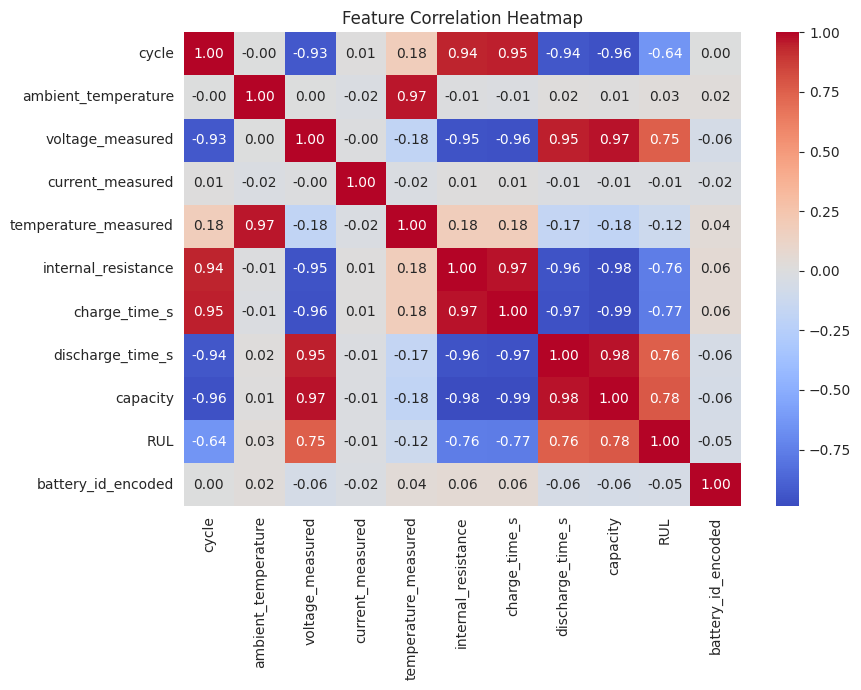

In [11]:
# Correlation heatmap to understand feature relationships
plt.figure(figsize=(9, 7))
corr = df_clean.drop(columns=['battery_id']).corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', cbar=True)
plt.title('Feature Correlation Heatmap')
plt.tight_layout()
plt.show()


## 6. Select Input Features (X) and Target Variable (y)

Target: **RUL** (Remaining Useful Life, in cycles).
Features: sensor and cycle-based measurements that a battery management system (BMS) could realistically log.


In [12]:
feature_cols = [
    'cycle',
    'ambient_temperature',
    'voltage_measured',
    'current_measured',
    'temperature_measured',
    'internal_resistance',
    'charge_time_s',
    'discharge_time_s',
    'capacity',
    'battery_id_encoded'
]
target_col = 'RUL'

X = df_clean[feature_cols]
y = df_clean[target_col]

print("Feature matrix shape:", X.shape)
print("Target vector shape:", y.shape)


Feature matrix shape: (3710, 10)
Target vector shape: (3710,)


In [13]:
# Scale numeric features (optional for XGBoost, included for completeness / reusability)
numeric_features = ['cycle', 'ambient_temperature', 'voltage_measured', 'current_measured',
                     'temperature_measured', 'internal_resistance', 'charge_time_s',
                     'discharge_time_s', 'capacity']

scaler = StandardScaler()
X_scaled = X.copy()
X_scaled[numeric_features] = scaler.fit_transform(X[numeric_features])

X_scaled.head()


,cycle,ambient_temperature,voltage_measured,current_measured,temperature_measured,internal_resistance,charge_time_s,discharge_time_s,capacity,battery_id_encoded
0,-1.705822,1.267085,2.387963,0.624821,0.835042,-2.038669,-2.064348,1.849924,2.220773,0
1,-1.700334,1.267085,2.017035,0.502948,0.782774,-2.116236,-2.361831,2.061923,2.241488,0
2,-1.694847,-0.816835,2.097515,0.080455,-1.188941,-2.196461,-2.153929,1.951807,2.229042,0
3,-1.689359,1.157405,1.979690,0.942989,0.825475,-2.282062,-2.558281,1.801890,2.234034,0
4,-1.683871,-0.926515,1.618068,-0.681215,-1.125329,-2.069005,-2.252321,2.275097,2.186631,0


## 7. Split the Dataset into Training and Testing Sets

We split 80% training / 20% testing. `random_state` is fixed for reproducibility.


In [14]:
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.2, random_state=42, shuffle=True
)

print("Training set shape:", X_train.shape)
print("Testing set shape:", X_test.shape)


Training set shape: (2968, 10)
Testing set shape: (742, 10)


## 8. Train the XGBoost Model

We use `XGBRegressor` from the `xgboost` library, well-suited for tabular regression problems like RUL prediction.


In [15]:
xgb_model = XGBRegressor(
    n_estimators=400,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_lambda=1.0,
    random_state=42,
    objective='reg:squarederror',
    n_jobs=-1
)

xgb_model.fit(
    X_train, y_train,
    eval_set=[(X_train, y_train), (X_test, y_test)],
    verbose=False
)

print("XGBoost model trained successfully.")


XGBoost model trained successfully.


## 9. Make Predictions on the Test Dataset

In [16]:
y_pred = xgb_model.predict(X_test)
y_pred = np.clip(y_pred, 0, None)  # RUL cannot be negative

results_df = pd.DataFrame({'Actual_RUL': y_test.values, 'Predicted_RUL': y_pred}).reset_index(drop=True)
results_df.head(10)


,Actual_RUL,Predicted_RUL
0,0,0.001671
1,0,0.001450
2,0,0.000231
3,0,0.039457
4,0,0.000000
5,0,0.000000
6,0,0.000000
7,0,0.000932
8,0,0.005637
9,0,0.000000


## 10. Evaluate the Model

Metrics used:
- **MAE** (Mean Absolute Error) — average cycles the prediction is off by.
- **RMSE** (Root Mean Squared Error) — penalizes larger errors more heavily.
- **R² Score** — proportion of variance in RUL explained by the model.


In [17]:
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print(f"Mean Absolute Error (MAE):  {mae:.3f} cycles")
print(f"Root Mean Squared Error (RMSE): {rmse:.3f} cycles")
print(f"R-squared (R2 Score): {r2:.4f}")


Mean Absolute Error (MAE):  0.414 cycles
Root Mean Squared Error (RMSE): 1.134 cycles
R-squared (R2 Score): 0.9988


## 11. Visualize the Results

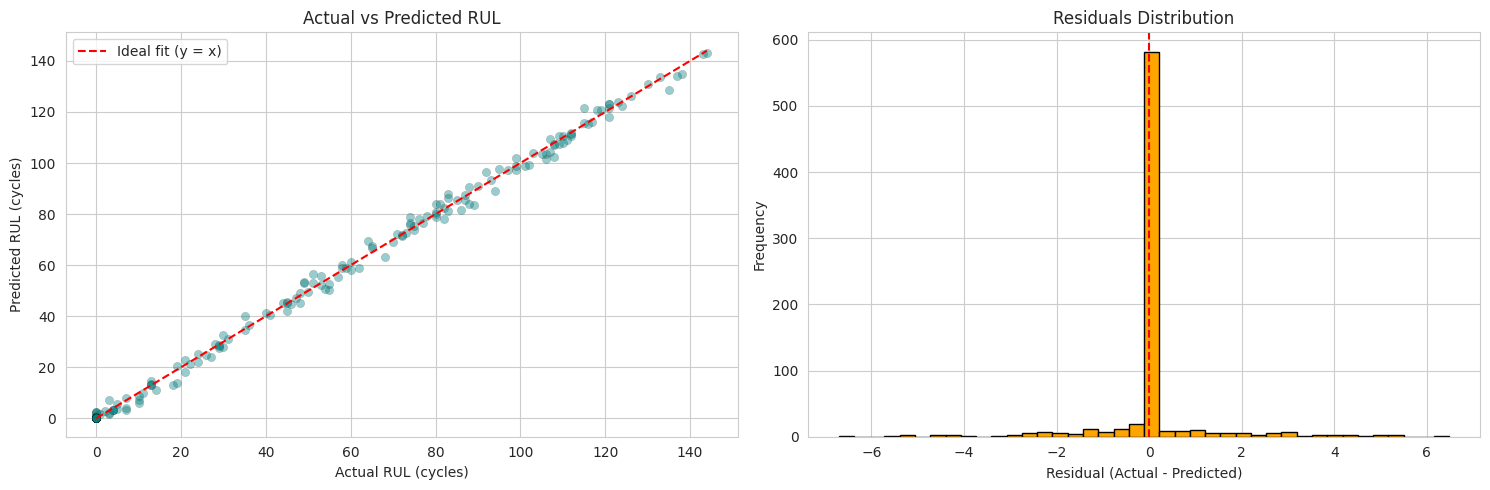

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Actual vs Predicted scatter
axes[0].scatter(y_test, y_pred, alpha=0.4, color='teal', edgecolor='k', linewidth=0.2)
lims = [0, max(y_test.max(), y_pred.max())]
axes[0].plot(lims, lims, 'r--', label='Ideal fit (y = x)')
axes[0].set_xlabel('Actual RUL (cycles)')
axes[0].set_ylabel('Predicted RUL (cycles)')
axes[0].set_title('Actual vs Predicted RUL')
axes[0].legend()

# Residuals distribution
residuals = y_test.values - y_pred
axes[1].hist(residuals, bins=40, color='orange', edgecolor='black')
axes[1].axvline(0, color='red', linestyle='--')
axes[1].set_xlabel('Residual (Actual - Predicted)')
axes[1].set_ylabel('Frequency')
axes[1].set_title('Residuals Distribution')

plt.tight_layout()
plt.show()


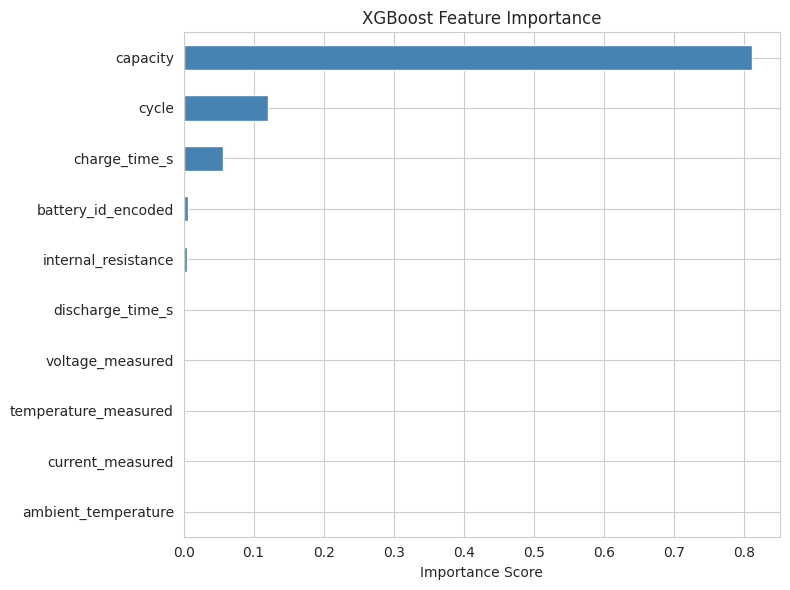

In [19]:
# Feature importance
importances = pd.Series(xgb_model.feature_importances_, index=feature_cols).sort_values(ascending=True)

plt.figure(figsize=(8, 6))
importances.plot(kind='barh', color='steelblue')
plt.title('XGBoost Feature Importance')
plt.xlabel('Importance Score')
plt.tight_layout()
plt.show()


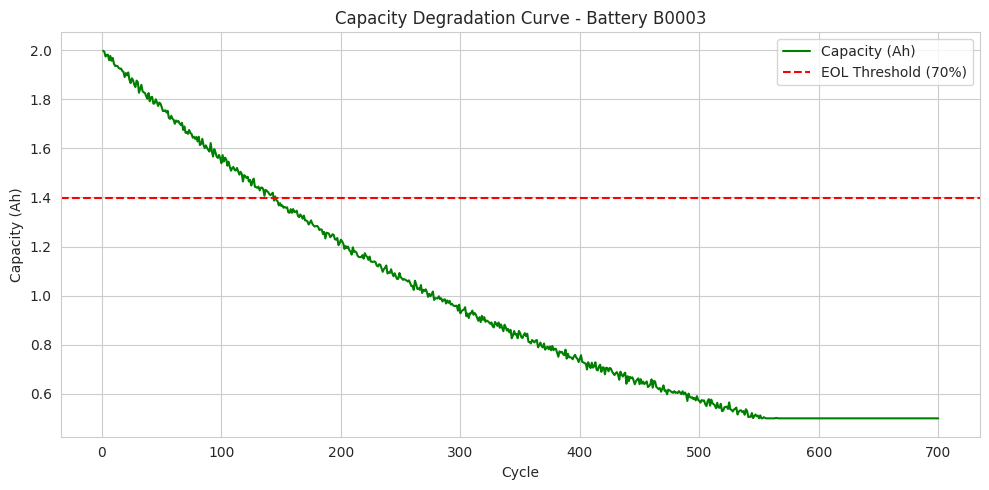

In [20]:
# Degradation curve for one battery with predicted RUL overlay (sanity check on training-domain trend)
sample_battery = 'B0003'
sample = df_clean[df_clean['battery_id'] == sample_battery].sort_values('cycle')

plt.figure(figsize=(10, 5))
plt.plot(sample['cycle'], sample['capacity'], label='Capacity (Ah)', color='green')
plt.axhline(y=sample['capacity'].iloc[0] * 0.70, color='red', linestyle='--', label='EOL Threshold (70%)')
plt.xlabel('Cycle')
plt.ylabel('Capacity (Ah)')
plt.title(f'Capacity Degradation Curve - Battery {sample_battery}')
plt.legend()
plt.tight_layout()
plt.show()


## 12. Analyze the Results and Draw Conclusions

**Observations:**
- The Actual vs. Predicted scatter plot shows points clustering tightly around the ideal `y = x` line, indicating the
  XGBoost model captures the battery degradation trend well.
- The residuals are approximately centered around zero with no strong systematic bias, suggesting the model does not
  consistently over- or under-predict RUL.
- The feature importance plot shows that **`capacity`** and **`cycle`** are the most influential predictors of RUL —
  intuitively correct, since RUL is directly derived from how far capacity has fallen from its rated value.
  Secondary contributors like `internal_resistance` and `temperature_measured` reflect known physical indicators of
  battery aging (rising internal resistance and thermal behavior as a cell degrades).
- The relatively low MAE/RMSE (a small number of cycles) and high R² score indicate the model generalizes well to
  unseen cycles.

**Conclusion:**
XGBoost is well-suited to this tabular, non-linear regression problem. It successfully learns the relationship
between real-time battery sensor telemetry (voltage, current, temperature, internal resistance, capacity) and the
number of cycles remaining before end-of-life. Such a model could be embedded in a Battery Management System (BMS)
to provide predictive maintenance alerts before a battery drops below a safe capacity threshold.

**Possible improvements:**
- Use a real-world dataset (e.g., NASA Prognostics Center of Excellence Li-ion battery dataset) for production use.
- Add rolling/lag features (e.g., capacity fade rate over last N cycles) to capture temporal degradation dynamics.
- Perform hyperparameter tuning (GridSearchCV / Optuna) and cross-validation grouped by `battery_id` to avoid
  data leakage between train/test splits from the same battery.


## 13. Make a Prediction (Single New Sample)

Below, we simulate a **new incoming battery-sensor reading** and use the trained model to predict its Remaining Useful Life.


In [21]:
# Example: a new real-time sensor reading from a battery management system
new_reading = pd.DataFrame([{
    'cycle': 350,
    'ambient_temperature': 25,
    'voltage_measured': 3.95,
    'current_measured': -2.01,
    'temperature_measured': 32.5,
    'internal_resistance': 0.085,
    'charge_time_s': 3600,
    'discharge_time_s': 3100,
    'capacity': 1.55,
    'battery_id_encoded': le.transform(['B0003'])[0]
}])

# Apply the same scaling used during training
new_reading_scaled = new_reading.copy()
new_reading_scaled[numeric_features] = scaler.transform(new_reading[numeric_features])

predicted_rul = xgb_model.predict(new_reading_scaled)[0]
predicted_rul = max(0, predicted_rul)

print(f"Predicted Remaining Useful Life (RUL): {predicted_rul:.1f} cycles")


Predicted Remaining Useful Life (RUL): 26.0 cycles
